# Decision tree: predicting whether adolescents cross the BDI-II threshold

**Research question:** what factors can predict whether or not adolescents cross the clinical threshold for depression according to the BDI-II?

This notebook applies the Week 7A material (decision trees and model complexity) to the project data. It uses the same target, features and train/test split as `logistic_regression.ipynb` and `knn.ipynb`, so the results can be compared directly.

**Learning goals (from Week 7A), applied here**
- Read a tree's questions, splits and leaves on the BDI data.
- Visualise an axis-aligned decision boundary.
- Compare shallow and deep trees using training and test accuracy.
- Explain why deeper trees can overfit.

---
## Step 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import recall_score

# Fixing the random seed makes the split and the trees reproducible
RANDOM_STATE = 42

---
## Step 2. Load data, define target and features

The target is `depressed` (1 if the BDI-II total is 14 or above, 0 if below). The seven features are the same as in the final linear regression and logistic regression models, after the multicollinearity fixes. `bdi_total` and the `bdi_item_*` columns are excluded because `depressed` is derived from them.

In [2]:
df = pd.read_csv("../data/processed/model_ready.csv")

feature_cols = [
    "screen_time_index", "est_leisure_screen_hours", "sex_binary",
    "sleep_quality_index", "avg_sleep_hours",
    "midsleep_weekend_hours", "social_jetlag_hours",
]
target = "depressed"   # 1 = BDI-II total >= 14, 0 = below

X = df[feature_cols]
y = df[target].astype(int)

print("X shape:", X.shape)
print(y.value_counts().rename({0: "not depressed", 1: "depressed"}))

X shape: (4810, 7)
depressed
not depressed    4023
depressed         787
Name: count, dtype: int64


---
## Step 3. Train/test split

Same settings as the other model notebooks (20% test, seed 42), so the test set is the same 962 adolescents.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

baseline_acc = (y_test == 0).mean()
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print(f"Baseline (always 'not depressed'): {baseline_acc:.1%}")

Training observations: 3848
Test observations: 962
Baseline (always 'not depressed'): 84.8%


## **Explanation**

- 3,848 adolescents are used to grow the tree and 962 are kept back to test it.
- Only about 1 in 6 adolescents is above the threshold, so a "model" that labels everyone *not depressed* is already right **84.8%** of the time. Every accuracy figure below has to be read against this baseline: a tree only adds value if it beats 84.8%, and ideally if it actually catches some of the depressed adolescents (recall).
- **Trees need no feature scaling** (unlike KNN): they compare each feature with a threshold, so it does not matter that sleep is in hours and screen time is on a 1–6 index.

---
## Step 4. Fit a small decision tree (max_depth = 3)

The tree asks at most three questions in a row. scikit-learn picks every question (which feature, which threshold) itself, choosing the split that makes the groups below it as pure as possible (lowest size-weighted Gini).

In [4]:
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)
print(f"Training accuracy: {tree.score(X_train, y_train):.3f}")
print(f"Test accuracy:     {tree.score(X_test, y_test):.3f}")
print(f"Baseline:          {baseline_acc:.3f}")
print(f"Recall (depressed): {recall_score(y_test, y_pred):.3f}  "
      f"-> caught {int(((y_pred == 1) & (y_test == 1)).sum())} of {int(y_test.sum())} real cases")

Training accuracy: 0.840
Test accuracy:     0.846
Baseline:          0.848
Recall (depressed): 0.048  -> caught 7 of 146 real cases


---
## Step 5. Read the tree

Each box shows:
- the **question** (go left if true, right if false)
- **gini**: how mixed the box is (0 = pure, 0.5 = a 50/50 mix)
- **samples**: how many training adolescents reach the box
- **value**: how many of them are [not depressed, depressed]
- **class**: the majority class, which is the prediction at a leaf

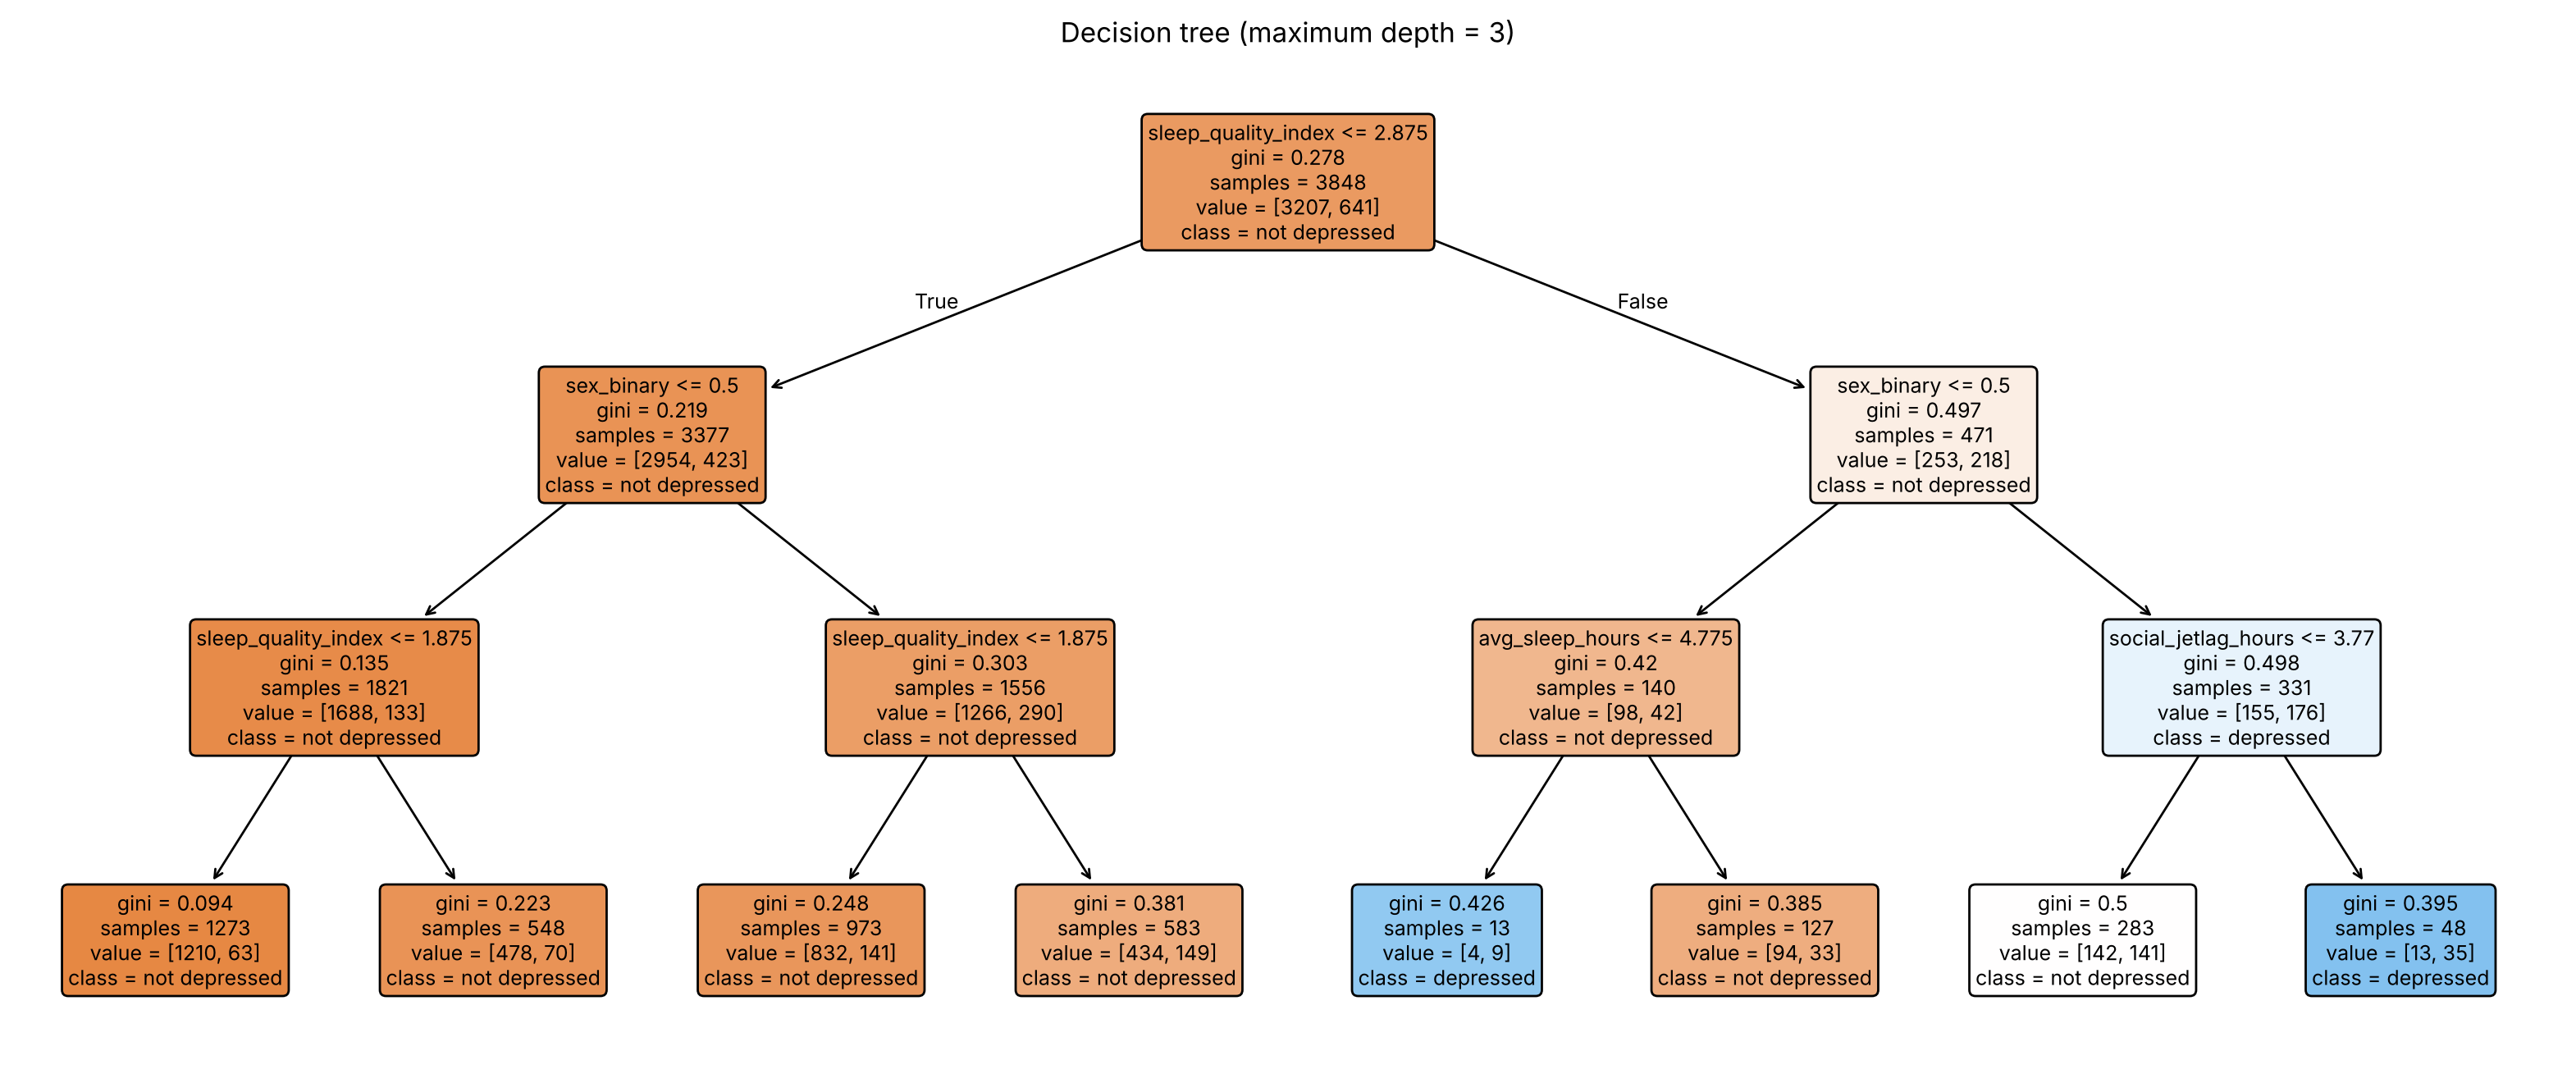

In [5]:
plt.figure(figsize=(20, 8))
plot_tree(
    tree,
    feature_names=feature_cols,
    class_names=["not depressed", "depressed"],
    filled=True,       # colour boxes by majority class
    rounded=True,
    proportion=False,  # show counts, not fractions
    fontsize=9,
)
plt.title("Decision tree (maximum depth = 3)")
plt.show()

## **Explanation: what the tree diagram shows**

**The questions the tree chose**
- **Root: `sleep_quality_index <= 2.875`.** Out of all seven features and every possible threshold, sleep quality gave the purest first split. It is the single most useful question for separating adolescents above and below the threshold.
- **Second level: `sex_binary <= 0.5`** on both sides (0.5 is just the midpoint between Boy = 0 and Girl = 1, so it means "is this a boy?"). Gender is the next most useful question.
- **Third level:** sleep quality again on the left; on the right, `avg_sleep_hours` (boys) and `social_jetlag_hours` (girls).

This matches the linear regression in `modelling.ipynb`, where sleep quality and gender had the largest effects. Screen time does not appear anywhere in the depth-3 tree.

**Box colours:** orange = majority *not depressed*, blue = majority *depressed*. The stronger the colour, the purer the box; a white box is a near 50/50 mix.

**Purity and the class imbalance**
- The root has 3,848 adolescents, about [3,207 not depressed, 641 depressed], so its Gini is only about **0.28**, already fairly "pure" simply because most adolescents are not depressed.
- After the first split, the right-hand box (poor sleep quality, 471 adolescents) is [253, 218]: **46% depressed**, compared with 13% on the left. Its Gini of 0.497 is close to the 0.5 maximum, so this split moved most of the depressed adolescents into a small, very mixed group.
- Moving down, the boxes on the right (poor sleep quality) and the girl branches become more mixed with depressed adolescents, which is the pattern the tree has found: **poorer sleep quality + being a girl → higher share above the threshold**.
- Even so, most leaves are still majority *not depressed*. For example, girls with sleep quality between 1.88 and 2.88 are [434, 149]: about 26% depressed, a much higher rate than the 5% among boys with good sleep [1,210, 63], but still a minority, so the leaf predicts "not depressed".

**Only two leaves predict "depressed"**
1. Poor sleep quality (> 2.875), boy, average sleep ≤ 4.78 hours: [4, 9], based on only **13** adolescents.
2. Poor sleep quality (> 2.875), girl, social jetlag > 3.77 hours: [13, 35], **48** adolescents.

Together these cover very few adolescents, which is why the tree catches only **7 of the 146** real cases in the test set (recall ≈ 0.05). One leaf, poor-sleep girls with lower social jetlag, is almost exactly 50/50 [142, 141] and tips to "not depressed" by a single adolescent.

**Scores:** training accuracy 0.840 and test accuracy 0.846 are close (no overfitting), but the test accuracy is slightly *below* the 0.848 baseline. The tree has found real patterns, yet as a classifier it is no better than predicting "not depressed" for everyone.

---
## Step 6. Visualise the decision boundary

A decision boundary can only be drawn in two dimensions, so for this picture a **separate depth-3 tree is fitted on just two features**: `sleep_quality_index` (the root feature above) and `social_jetlag_hours`. The background is coloured by what this tree predicts for every point on a fine grid; the dots are the training adolescents.

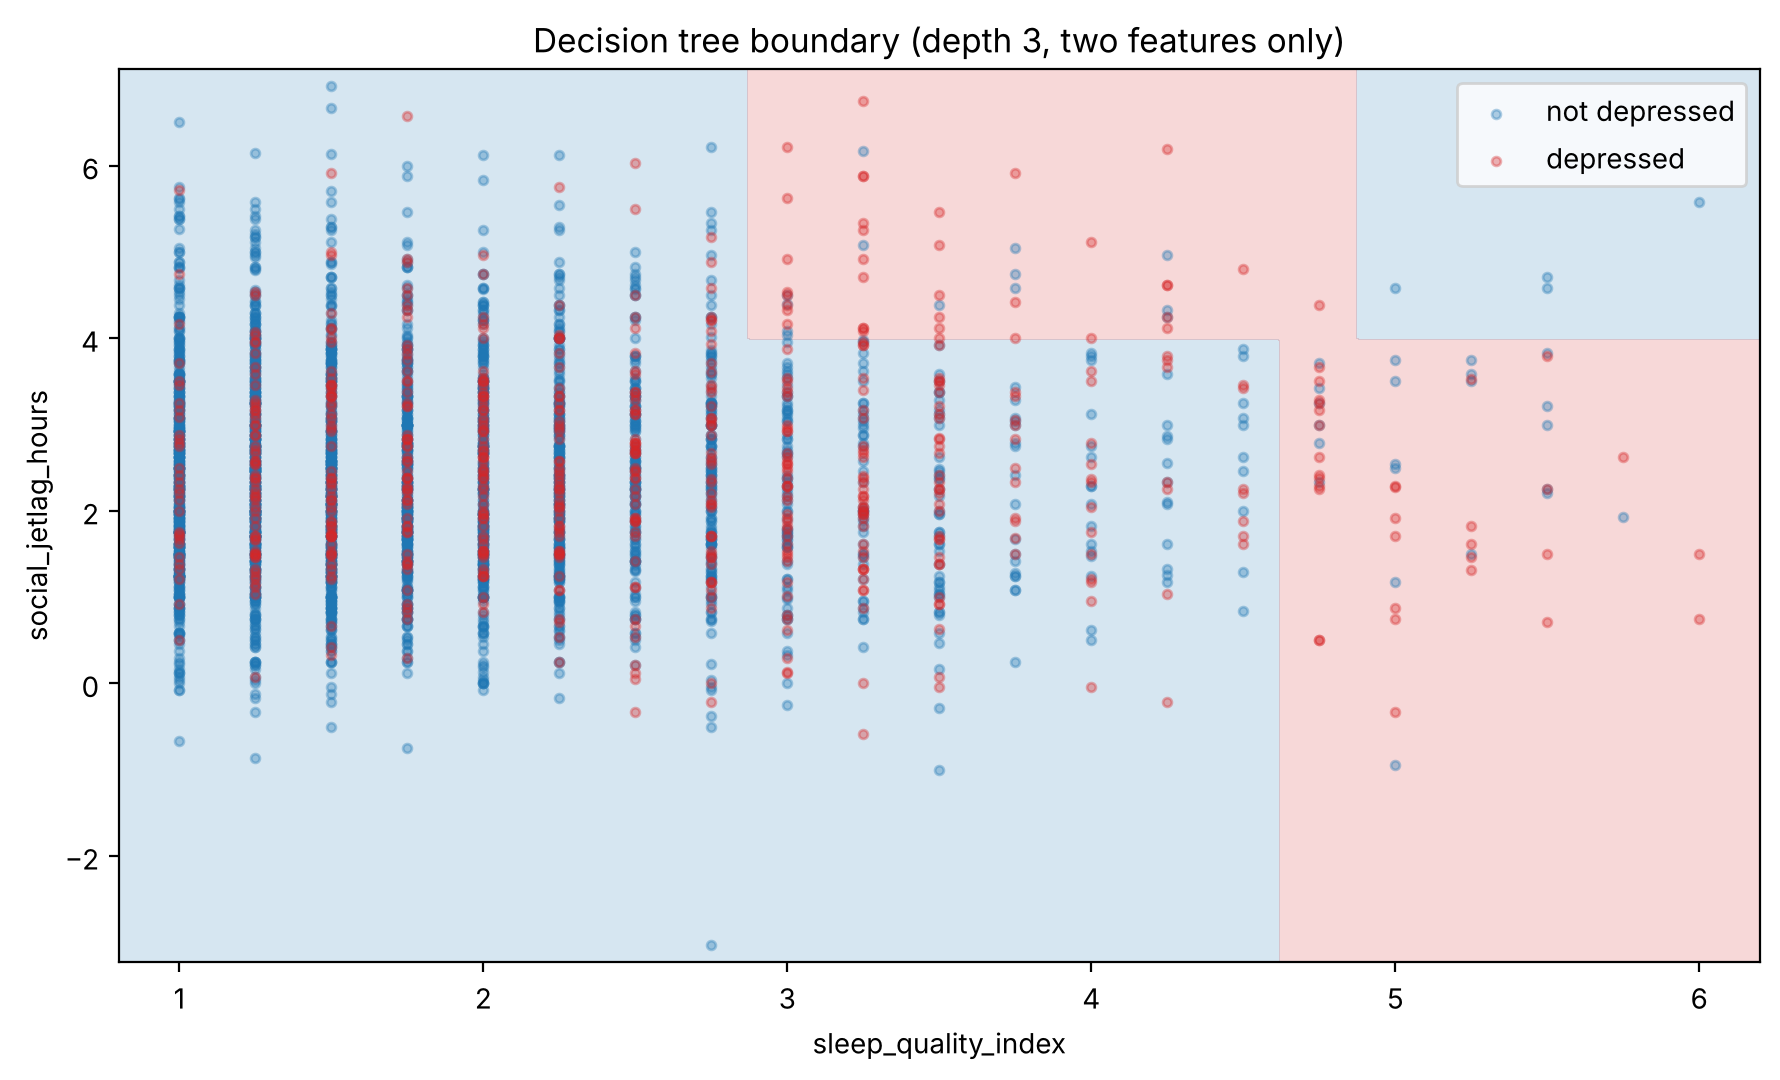

In [6]:
def plot_tree_boundary(model, X_plot, y_plot, x_col, y_col, title, ax):
    """Colour the feature space by the model's prediction and overlay the adolescents."""
    # 1) Build a grid of points covering the data
    x_min, x_max = X_plot[x_col].min() - 0.2, X_plot[x_col].max() + 0.2
    y_min, y_max = X_plot[y_col].min() - 0.2, X_plot[y_col].max() + 0.2
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = pd.DataFrame({x_col: xx.ravel(), y_col: yy.ravel()})

    # 2) Predict a class for every grid point and colour the background
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5],
                cmap=ListedColormap(["tab:blue", "tab:red"]))

    # 3) Overlay the actual adolescents (depressed drawn last so they are visible)
    for label, name, colour in [(0, "not depressed", "tab:blue"), (1, "depressed", "tab:red")]:
        subset = X_plot.loc[y_plot == label]
        ax.scatter(subset[x_col], subset[y_col], label=name, color=colour, alpha=0.35, s=10)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(title)

boundary_cols = ["sleep_quality_index", "social_jetlag_hours"]
tree_2d = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree_2d.fit(X_train[boundary_cols], y_train)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_tree_boundary(tree_2d, X_train[boundary_cols], y_train, *boundary_cols,
                   "Decision tree boundary (depth 3, two features only)", ax)
ax.legend()
plt.tight_layout()
plt.show()

## **Explanation: what the boundary plot shows**

- **Axes:** sleep quality index on the x-axis (higher = more disturbed sleep), social jetlag in hours on the y-axis (the gap between weekday and weekend sleep timing).
- **Background colour:** the tree's prediction. Blue = predicted *not depressed*, red = predicted *depressed*.
- **Rectangles:** every edge is perfectly vertical or horizontal, because each question asks about one feature only ("is sleep quality ≤ 2.88?"). The tree can only cut straight across one axis at a time, so its regions are always boxes.
- **Colours here are the reverse of the tree diagram:** in this plot red means *depressed* and blue *not depressed*.
- **Where the red region sits:** only on the **right-hand side** (poor sleep quality, above about 2.9). Between about 2.9 and 4.6 it is red only when social jetlag is above about 4 hours; above 4.6 it is red when jetlag is below 4 hours. This is the same message as the full tree: sleep quality is the feature doing most of the work, and other features only matter once sleep quality is poor.
- **The small blue box at the top right** (very poor sleep and high jetlag) is based on only a handful of adolescents. Rules built on so few people are a first sign of a tree fitting individual cases rather than a general pattern.
- **The overlap problem:** red dots (depressed adolescents) are scattered right across the blue area, mixed in with blue dots. There is no clean region where depressed adolescents are the majority, which is why the tree predicts "depressed" so rarely. Two features cannot separate the groups well, and the full seven-feature tree has the same difficulty.
- The vertical stripes of dots appear because sleep quality is an average of four 1–6 ratings, so it only takes values in steps of 0.25.

---
## Step 7. Core investigation: tree depth

The same tree is refitted with `max_depth` from 1 to 20, recording training accuracy, test accuracy, test recall and the number of leaves (how complex the tree is).

In [7]:
results = []
for depth in range(1, 21):
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    results.append({
        "max_depth": depth,
        "Training accuracy": model.score(X_train, y_train),
        "Test accuracy": model.score(X_test, y_test),
        "Test recall (depressed)": recall_score(y_test, model.predict(X_test)),
        "Leaves": model.get_n_leaves(),   # number of final groups = how complex the tree is
    })

tree_results = pd.DataFrame(results)
tree_results.round(3)

,max_depth,Training accuracy,Test accuracy,Test recall (depressed),Leaves
0,1,0.833,0.848,0.000,2
1,2,0.839,0.828,0.205,4
2,3,0.840,0.846,0.048,8
3,4,0.845,0.828,0.192,16
4,5,0.850,0.844,0.082,31
5,6,0.859,0.842,0.096,54
6,7,0.865,0.840,0.096,85
7,8,0.876,0.836,0.130,124
8,9,0.884,0.834,0.137,166
9,10,0.895,0.833,0.178,218


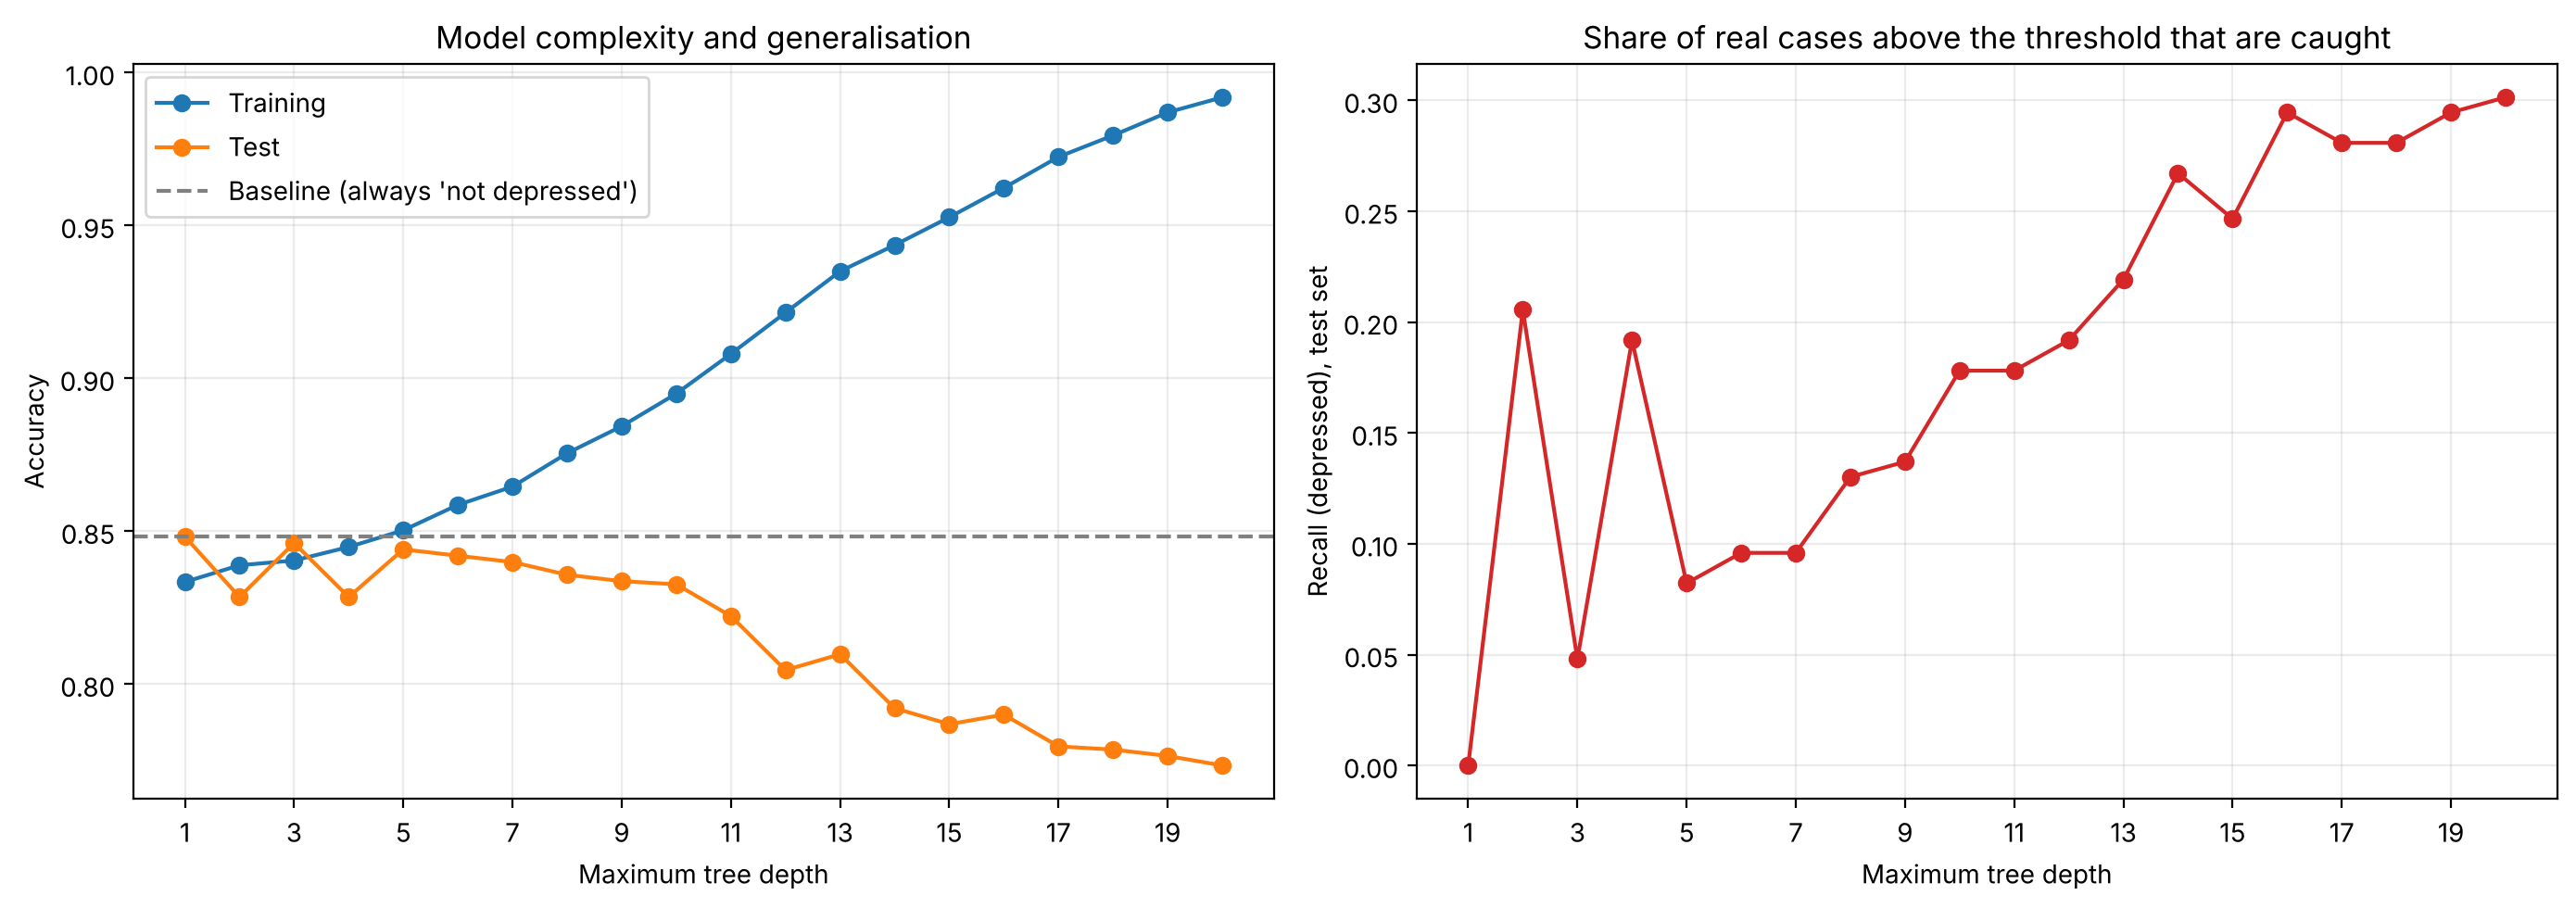

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: accuracy against depth, with the baseline for reference
axes[0].plot(tree_results["max_depth"], tree_results["Training accuracy"], marker="o", label="Training")
axes[0].plot(tree_results["max_depth"], tree_results["Test accuracy"], marker="o", label="Test")
axes[0].axhline(baseline_acc, color="grey", linestyle="--", label="Baseline (always 'not depressed')")
axes[0].set_xlabel("Maximum tree depth")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Model complexity and generalisation")
axes[0].set_xticks(range(1, 21, 2))
axes[0].grid(alpha=0.25)
axes[0].legend()

# Right: how many real cases are caught at each depth
axes[1].plot(tree_results["max_depth"], tree_results["Test recall (depressed)"], marker="o", color="tab:red")
axes[1].set_xlabel("Maximum tree depth")
axes[1].set_ylabel("Recall (depressed), test set")
axes[1].set_title("Share of real cases above the threshold that are caught")
axes[1].set_xticks(range(1, 21, 2))
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## **Explanation: reading the depth table and the two charts**

**Left chart: accuracy against depth**
- **Training accuracy (blue) rises steadily**, from 0.833 at depth 1 to 0.992 at depth 20. Every extra level lets the tree make more specific rules, until it is close to memorising the training adolescents. The number of leaves shows this: 2 leaves at depth 1, 8 at depth 3, 218 at depth 10, 639 at depth 20.
- **Test accuracy (orange) never rises with depth.** It sits just under the baseline from depth 4 to 10 (0.844 → 0.833) and then falls faster, down to 0.773 at depth 20, well *below* the 0.848 baseline. This widening gap between the two lines is **overfitting**: the deep tree has learned rules that only hold for particular training adolescents (many leaves contain one or two people), and those rules make mistakes on new adolescents.
- **At depths 1–4 the test line is above the training line.** This is not a sign of a good model: the test set happens to contain slightly fewer depressed adolescents (15.2%) than the training set (16.7%), and a tree that predicts "not depressed" almost everywhere scores higher when there are fewer depressed adolescents to miss.
- **The grey dashed baseline is never clearly beaten.** The highest test accuracy is at **depth 1 (0.848)**, which equals the baseline exactly because that tree predicts "not depressed" for everyone. Picking the depth with the highest test accuracy would therefore pick a model that catches nobody, showing that **accuracy alone is misleading with imbalanced classes**.

**Right chart: recall against depth**
- At depth 1 recall is **0**: no depressed adolescent is caught.
- Recall is bumpy at small depths (0.21 at depth 2 but 0.05 at depth 3, because a single split can switch a large leaf between "depressed" and "not depressed"), then generally **rises with depth** (0.18 at depth 10, 0.30 at depth 20). Deeper trees make small, specific leaves, some of which are majority-depressed, so the tree flags more adolescents.
- But the left chart shows the cost: those extra flags come with many more false alarms, so overall accuracy drops. The deeper tree is not better; it trades one kind of error for another while overfitting.

**Compared with the lecturer's dataset:** with 962 test adolescents, one adolescent is worth only about 0.1 percentage points, so the test curve here is much smoother than in the Week 7 example (60 students, about 1.7 points each). The pattern of rising training accuracy, peaking then falling test accuracy and a widening gap is the same.

In [9]:
best = tree_results.loc[tree_results["Test accuracy"].idxmax()]
print("Best depth on this test set (by accuracy):", int(best["max_depth"]))
print(f"Test accuracy: {best['Test accuracy']:.3f}  |  recall: {best['Test recall (depressed)']:.3f}")

Best depth on this test set (by accuracy): 1
Test accuracy: 0.848  |  recall: 0.000


> **Caveat (as in Week 7A):** choosing the depth by looking at the test set makes the test set less "unseen". Week 10 introduces cross-validation, the proper way to choose settings like this.

---
## Step 8. Save results for the comparison notebook

The depth-3 tree (the model read in Steps 4–6) is saved in the same format as `logistic_regression.ipynb` and `knn.ipynb`, so `model_comparison.ipynb` can compare all three on the same test set.

In [10]:
import os
os.makedirs("../results", exist_ok=True)

pd.DataFrame({
    "actual": y_test.values,
    "predicted": tree.predict(X_test),
    "prob_depressed": tree.predict_proba(X_test)[:, 1],
}, index=y_test.index).to_csv("../results/tree_predictions.csv", index_label="row")

print("Saved ../results/tree_predictions.csv")

Saved ../results/tree_predictions.csv


---
## Summary of findings

- The tree's own choice of questions confirms the regression results: **sleep quality is the most useful feature, followed by gender**; poorer sleep quality and being a girl go with a higher share of adolescents above the threshold. Screen time is not used at depth 3.
- As a classifier, the depth-3 tree is **not useful on its own**: test accuracy 0.846 against a 0.848 baseline, and only 7 of 146 real cases caught (recall ≈ 0.05). Logistic regression (recall 0.16) and KNN (recall 0.17) caught more.
- The depth investigation shows **overfitting** clearly: training accuracy climbs to 0.99 while test accuracy falls to 0.77, below the baseline.
- Because of the class imbalance, the depth with the "best" test accuracy (depth 1) is a tree that predicts nobody is depressed, so accuracy should always be read together with the baseline and recall.